# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import os

# Download latest version
path = kagglehub.dataset_download("azminetoushikwasi/-lionel-messi-all-club-goals")

print("Path to dataset files:", path)

# Load dataset
df = pd.read_csv(os.path.join(path, 'data.csv'))

print("--- 1. FIRST 5 ROWS (df.head()) ---")
print(df.head())

Using Colab cache for faster access to the '-lionel-messi-all-club-goals' dataset.
Path to dataset files: /kaggle/input/-lionel-messi-all-club-goals
--- 1. FIRST 5 ROWS (df.head()) ---
  Season            Competition     Matchday      Date Venue          Club  \
0  04/05                 LaLiga           34  05-01/05     H  FC Barcelona   
1  05/06  UEFA Champions League  Group Stage  11-02/05     H  FC Barcelona   
2  05/06                 LaLiga           13  11/27/05     H  FC Barcelona   
3  05/06                 LaLiga           19   1/15/06     H  FC Barcelona   
4  05/06                 LaLiga           20   1/22/06     H  FC Barcelona   

               Opponent Result Playing_Position Minute At_score  \
0     Albacete Balompie   2:00               CF   90+1     2:00   
1  Panathinaikos Athens   5:00               RW     34     3:00   
2      Racing Santander   4:01               RW     51     2:00   
3       Athletic Bilbao   2:01               RW     50     2:01   
4      Depo

## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(704, 13)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 704 entries, 0 to 703
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Season            704 non-null    object
 1   Competition       704 non-null    object
 2   Matchday          704 non-null    object
 3   Date              704 non-null    object
 4   Venue             704 non-null    object
 5   Club              704 non-null    object
 6   Opponent          704 non-null    object
 7   Result            704 non-null    object
 8   Playing_Position  704 non-null    object
 9   Minute            704 non-null    object
 10  At_score          704 non-null    object
 11  Type              703 non-null    object
 12  Goal_assist       490 non-null    object
dtypes: object(13)
memory usage: 71.6+ KB


In [ ]:
df.describe()

,Season,Competition,Matchday,Date,Venue,Club,Opponent,Result,Playing_Position,Minute,At_score,Type,Goal_assist
count,704,704,704,704,704,704,704,704,704,704,704,703,490
unique,19,10,48,455,2,2,98,55,9,97,46,12,71
top,11-Dec,LaLiga,Group Stage,03/07/12,H,FC Barcelona,Sevilla FC,4:00,CF,55,1:00,Left-footed shot,Luis Suarez
freq,73,474,80,5,420,672,38,47,276,14,98,436,48


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra `num` de 0 (sem doença) a 4 (graus diferentes de doença). Pra hoje, vamos simplificar para uma variável binária, presença ou ausência de doença cardíaca, já que é essa a distinção que vamos usar nas cores ao longo da aula (rosa = sem doença, roxo = com doença).

In [ ]:
import numpy as np

# Definindo nossa classe alvo de análise:
# Analisaremos se o gol do Messi foi fruto de assistência ou se foi uma jogada individual/sem assistência direta registrada.
df["participacao_gols"] = np.where(df["Goal_assist"].isna(), "Gol Individual / Sem Assistência", "Gol com Assistência")

print("Contagem por classe de análise:")
print(df["participacao_gols"].value_counts())
print("\nProporção das classes:")
print(df["participacao_gols"].value_counts(normalize=True).round(3))

# Exibe as primeiras linhas para verificar a coluna criada
df.head()

Contagem por classe de análise:
participacao_gols
Gol com Assistência                 490
Gol Individual / Sem Assistência    214
Name: count, dtype: int64

Proporção das classes:
participacao_gols
Gol com Assistência                 0.696
Gol Individual / Sem Assistência    0.304
Name: proportion, dtype: float64


,Season,Competition,Matchday,Date,Venue,Club,Opponent,Result,Playing_Position,Minute,At_score,Type,Goal_assist,participacao_gols
0,04/05,LaLiga,34,05-01/05,H,FC Barcelona,Albacete Balompie,2:00,CF,90+1,2:00,Left-footed shot,Ronaldinho Gaacho,Gol com Assistência
1,05/06,UEFA Champions League,Group Stage,11-02/05,H,FC Barcelona,Panathinaikos Athens,5:00,RW,34,3:00,Left-footed shot,NaN,Gol Individual / Sem Assistência
2,05/06,LaLiga,13,11/27/05,H,FC Barcelona,Racing Santander,4:01,RW,51,2:00,Left-footed shot,Samuel Etoo,Gol com Assistência
3,05/06,LaLiga,19,1/15/06,H,FC Barcelona,Athletic Bilbao,2:01,RW,50,2:01,Left-footed shot,Mark van Bommel,Gol com Assistência
4,05/06,LaLiga,20,1/22/06,H,FC Barcelona,Deportivo Alaves,2:00,CF,82,2:00,Left-footed shot,Ronaldinho Gaacho,Gol com Assistência


## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
Season,0
Competition,0
Matchday,0
Date,0
Venue,0
Club,0
Opponent,0
Result,0
Playing_Position,0
Minute,0


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: não tenho ideia do porquê está faltando um dado no "Type", já que este representa a maneira como o jogador fez o gol (se foi com o pé esquerdo, pé direito, de cabeça, etc). Já "Goal_assist" há dados faltantes pois Messi fez gols "sozinhos", sem ninguém dar passe para ele.

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos uma feature 'stage'com dados ausentes.

Pela fonte de dados observamos que:

* stage - estágios ou fases de cada campeonato

*Como os dados foram coletados:*

- O conjunto de dados foi coletado pelo autor do csv original. Eu consegui o acesso através do link do Kaggle.

*Qual a natureza da fonte de dados:*
- Considerando que os dados são do jogador Lionel Messi, sabemos que ele jogou várias partidas, fez muitos gols e deu muitas assistências. Portanto, a natureza da fonte dos dados se trata das informações do jogador entre os anos de 2005 (sua estreia) a 2023.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['Type', 'Goal_assist']
Type             1
Goal_assist    214
dtype: int64


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

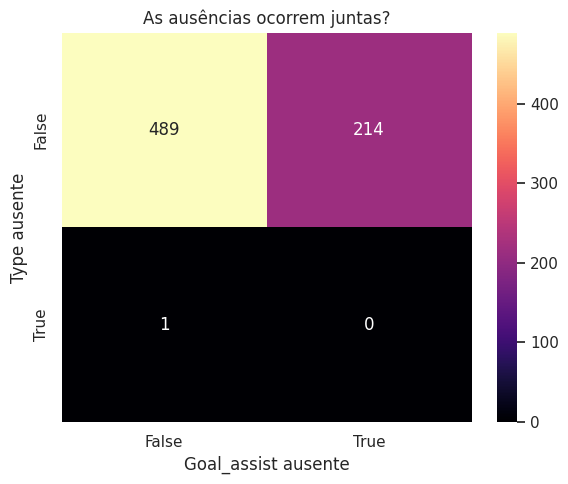

In [ ]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display

# Tratando a coluna 'Minute' para transformá-la em uma variável quantitativa numérica
# Removemos os acréscimos (ex: '90+1' vira 90) para analisar o tempo regulamentar bruto do gol
df["Minute_clean"] = df["Minute"].apply(lambda x: int(str(x).split('+')[0]) if str(x).replace('+', '').isdigit() else np.nan)

# Atualizando as colunas para o dataset atual do Lionel Messi
VARS_QUANT = ["Minute_clean"]
VARS_QUALI = ["Season", "Competition", "Matchday", "Venue", "Club", "Opponent", "Playing_Position", "Type", "Goal_assist", "participacao_gols"]

### Tabela descritiva, com assimetria e curtose das variáveis quantitativas

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

# Usamos display para renderizar o Styler HTML de forma correta no notebook
estilo_desc = (
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

display(estilo_desc)

,mean,median,std,min,max,skewness,kurtosis
Minute_clean,51.83,54.00,25.82,3.00,110.00,-0.12,-1.20


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)?

Aqui está a análise da única variável quantitativa (Minute_clean - o minuto em que o gol foi marcado):

Média: ~51,8 minutos
Mediana (50%): 54 minutos
Mínimo / Máximo: de 3 a 110 minutos
Assimetria (skewness): -0.12 (indica uma distribuição quase perfeitamente simétrica em relação ao tempo dos gols)
Curtose: -1.20 (indica uma curva do tipo platicúrtica, ou seja, mais achatada, o que sugere que os gols de Messi são distribuídos de maneira bem constante ao longo de quase todo o tempo regulamentar, sem um único pico extremo).

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


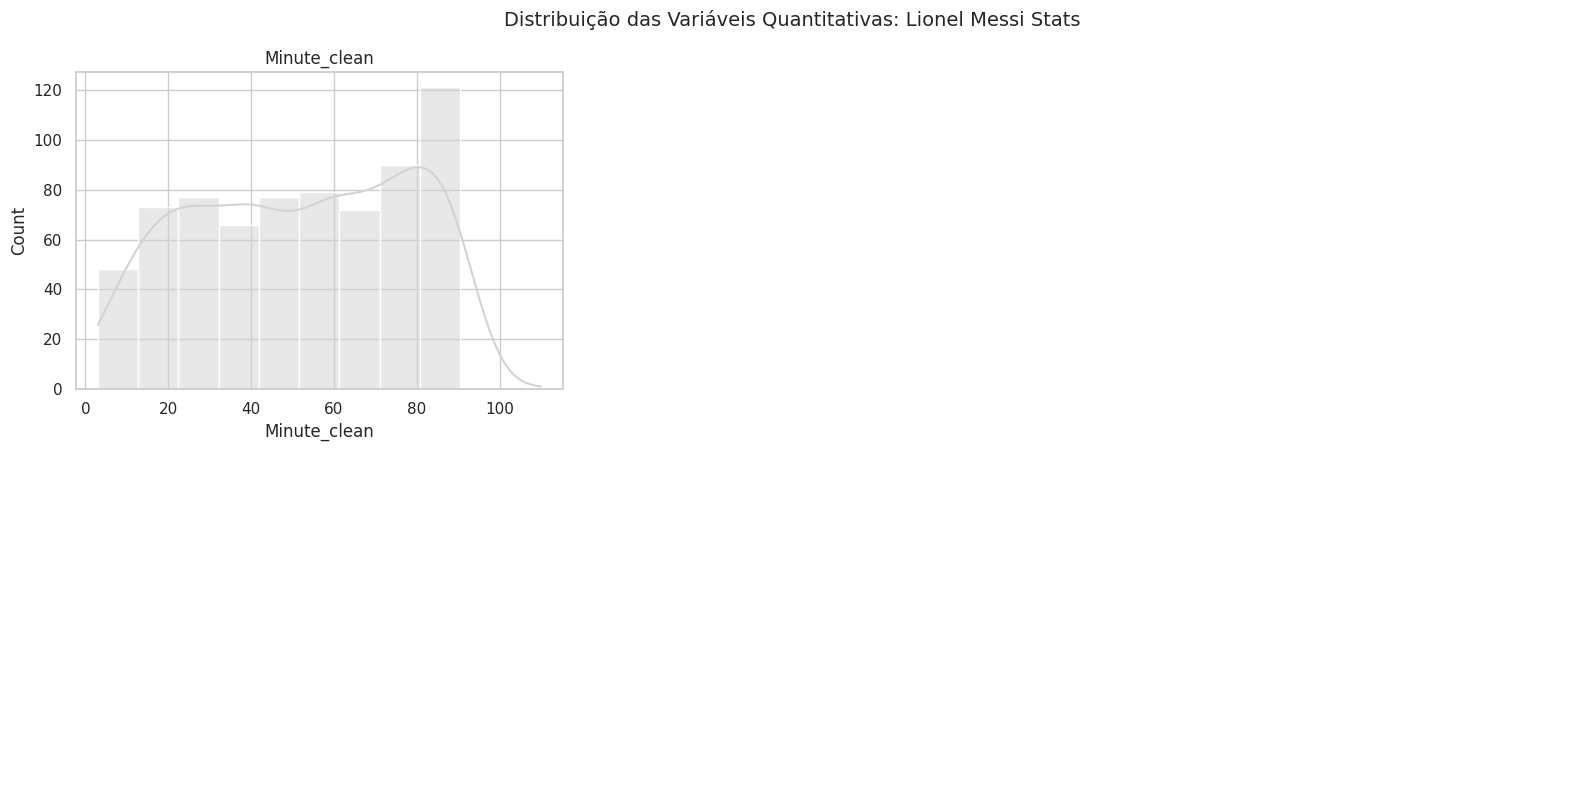

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de subplots baseada na quantidade de variáveis quantitativas
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

# Esconde eixos vazios se houver menos variáveis que espaços no grid
for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Lionel Messi Stats", fontsize=14)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Normal" e "Cardíaco"?

nesse caso, a distribuição não permite analisar pois só há uma variável quantitativa.

a análise mais próxima que pode ser feita nesse gráfico é: a maioria dos gols saíram após o minuto 80, o que representa o poder de decisão elevado do Messi.

#### Testes de Aderência

*Será se o colesterol segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

Shapiro-Wilk — Minute_clean: estatística=0.9498, p-valor=9.687e-15
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


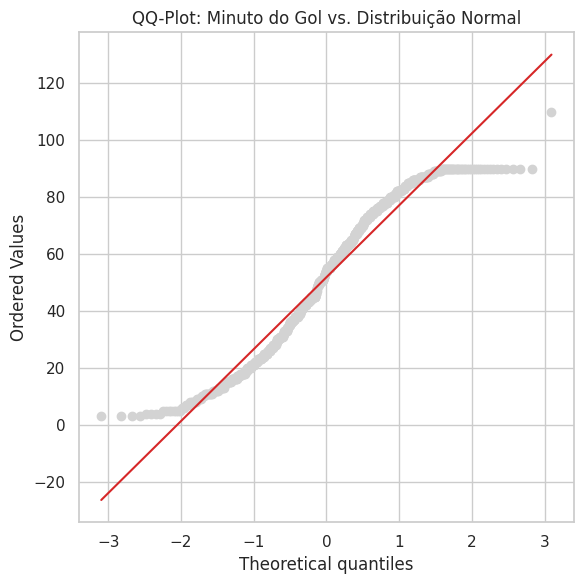

In [ ]:
# Testando normalidade para a variável 'Minute_clean' do dataset do Messi
stat_sw, p_valor_sw = stats.shapiro(df["Minute_clean"].dropna())
print(f"Shapiro-Wilk — Minute_clean: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — Minute_clean"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["Minute_clean"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Minuto do Gol vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

Resultados do Teste de Normalidade:
Shapiro-Wilk: Estatística = 0.9498 | p-valor = 9.687e-15
Decisão: Rejeita H0 (normalidade) com muita folga ($̑ = 0.05$$̑ = 0.05$).
O que isso significa na prática?
- Distribuição não é Normal: Embora tenhamos observado anteriormente que a distribuição é quase simétrica (assimetria de apenas -0.12), o teste estatístico Shapiro-Wilk aponta com extrema certeza que os minutos dos gols de Messi não seguem uma curva normal (gaussiana) perfeita.
- Visualização (QQ-Plot): No gráfico gerado, podemos notar que os pontos se desviam da linha diagonal vermelha principalmente nos extremos superiores e inferiores, além de possuir um formato achatado (platicúrtico, curtose de -1.20), confirmando a rejeição do teste de aderência.

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
Minute_clean,0.9498,0.0,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

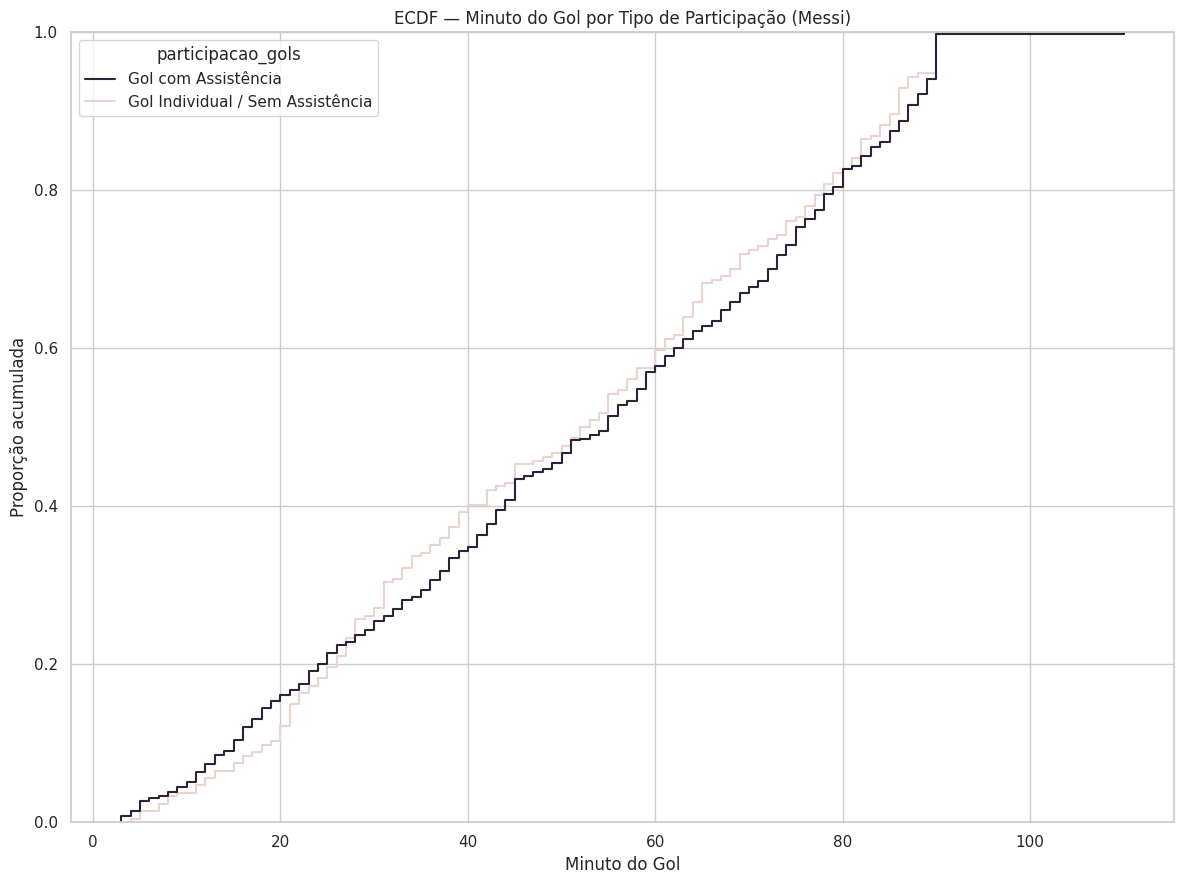

In [ ]:
plt.figure(figsize=(12, 9))
# Adaptando para o dataset do Messi: usando 'Minute_clean' e 'participacao_gols'
sns.ecdfplot(data=df, x="Minute_clean", hue="participacao_gols",
             palette={"Gol com Assistência": COR_DESTAQUE, "Gol Individual / Sem Assistência": COR_CONTEXTO})
plt.title("ECDF — Minuto do Gol por Tipo de Participação (Messi)")
plt.xlabel("Minuto do Gol")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos pacientes desse grupo tem colesterol até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de colesterol onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

O que essa ECDF nos mostra na prática?
Eixo X (Minuto do Gol): Mostra a evolução do tempo regulamentar da partida (de 0 a 90+ minutos).
Eixo Y (Proporção Acumulada): Representa a porcentagem acumulada de gols marcados até aquele minuto.
Comparação de Curvas:
A curva escura (gols com assistência) e a curva rosa (gols individuais) caminham de forma extremamente paralela e próxima durante quase todo o gráfico.
Isso indica que a distribuição temporal dos gols não muda de forma significativa dependendo de como o gol foi construído. Seja recebendo passe ou criando a jogada sozinho, o Messi distribui a criação e finalização desses gols de maneira muito similar ao longo dos 90 minutos de jogo.

### Métricas de Tendêncial Central

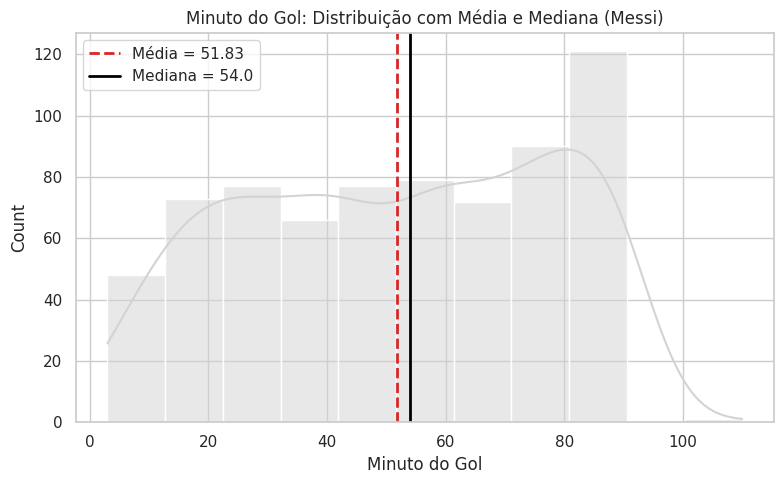

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculando métricas para a variável 'Minute_clean' do Messi
media_minuto = df["Minute_clean"].mean()
mediana_minuto = df["Minute_clean"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Minute_clean", kde=True, color=COR_NEUTRA)
plt.axvline(media_minuto, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_minuto:.2f}")
plt.axvline(mediana_minuto, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_minuto:.1f}")
plt.title("Minuto do Gol: Distribuição com Média e Mediana (Messi)")
plt.xlabel("Minuto do Gol")
plt.legend()
plt.tight_layout()
plt.show()

Interpretação do Histograma:
Média (~51,82 minutos): Mostrada pela linha tracejada vermelha.
Mediana (54,0 minutos): Mostrada pela linha sólida preta.
Distribuição:
As duas linhas (Média e Mediana) estão muito próximas uma da outra, reforçando visualmente a simetria que identificamos pelo índice de assimetria próximo de zero (-0.12).
No entanto, o formato do gráfico não possui o pico clássico de uma distribuição normal (curva de sino); ao contrário, ele é bastante plano e bem distribuído de forma constante ao longo de todo o tempo regulamentar. Isso confirma o porquê do teste de Shapiro-Wilk ter rejeitado a normalidade — a distribuição é praticamente uniforme/achatada, em vez de gaussiana.

### Dispersão

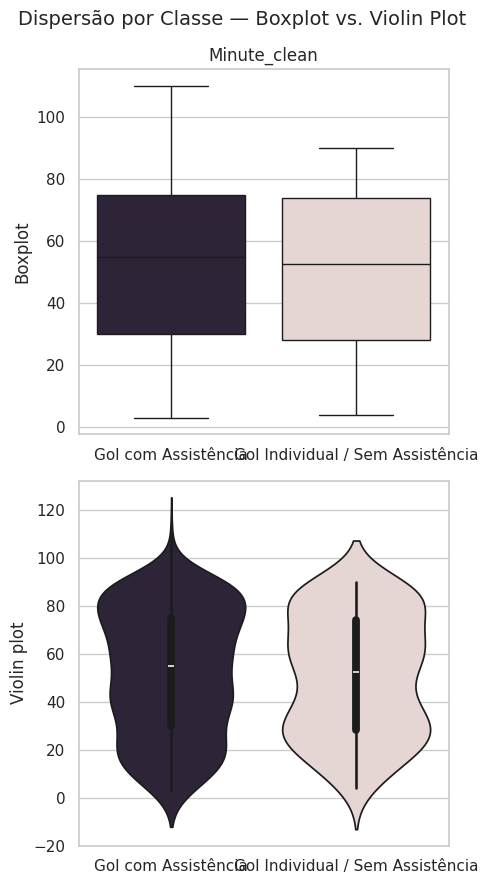

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por classe"""

palette_classe = {"Gol com Assistência": COR_DESTAQUE, "Gol Individual / Sem Assistência": COR_CONTEXTO}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(5 * len(VARS_QUANT), 9), squeeze=False)

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="participacao_gols", y=col, hue="participacao_gols",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="participacao_gols", y=col, hue="participacao_gols",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Normal" e "Cardíaco"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

O que esses gráficos nos mostram sobre os gols do Messi?
Simetria e Distribuição Semelhante: Tanto no Boxplot (painel superior) quanto no Violin Plot (painel inferior), observamos que a mediana e os quartis (caixa) estão posicionados de forma quase idêntica para as duas classes: Gol com Assistência (roxo escuro) e Gol Individual / Sem Assistência (rosa claro).
Intervalo Interquartil (IQR): O meio do jogo (entre os minutos 30 e 75) concentra a maior parte dos gols de ambos os tipos. Isso nos mostra que a dispersão temporal dos gols criados de forma individual não difere dos gols originados por passes de companheiros.
Ausência de Outliers Univariados: Não vemos pontos isolados (outliers) além das linhas limites do Boxplot, o que faz sentido clínico/esportivo, já que todos os gols válidos ocorrem rigorosamente dentro do intervalo de tempo regulamentar do futebol (0 a 90+ minutos).

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
Minute_clean,-37.5,142.5,0.0


### Visualizando os Outliers

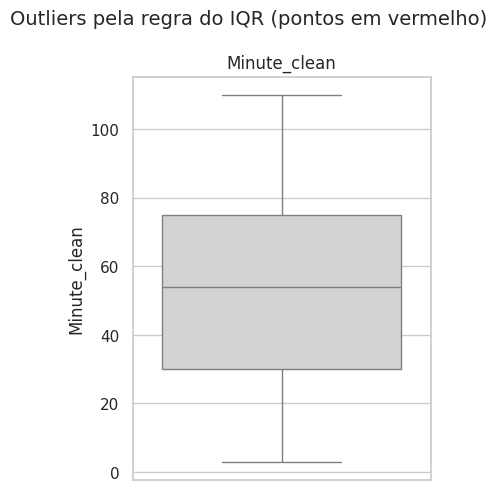

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5), squeeze=False)

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[0, i])
    axes[0, i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `chol` e `oldpeak`): eles parecem fisiologicamente plausíveis (pacientes reais podem ter colesterol muito alto), ou parecem violar algum limite físico conhecido? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.

O que essa análise de outliers nos mostra?
Sem Outliers Estatísticos pelo Método IQR: O boxplot da variável Minute_clean (o minuto do gol) não apresenta nenhum ponto marcado em vermelho (outliers).
Limites Teóricos vs. Práticos: A regra clássica do IQR define os limites teóricos como [-37.5, 142.5]. Como as partidas de futebol duram regulamentarmente entre 0 e 90 minutos (mais acréscimos), os valores práticos da variável sempre estarão contidos de forma segura dentro desse intervalo estatístico.
Conclusão: Não existem discrepâncias temporais aberrantes. Cada registro representa um gol legítimo dentro do tempo regulamentar da partida.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável para `ca`/`thal` é MAR ou MCAR (não MNAR), e o volume é pequeno (poucas linhas em ~300). Com essas duas informações juntas, a decisão pragmática é remover as linhas afetadas — o risco de viés é baixo (mecanismo provavelmente não depende do próprio valor ausente) e o custo de perder ~2% das linhas é pequeno.

In [ ]:
linhas_antes = df.shape[0]
df_antes = df.copy()
# No dataset atual do Messi, a coluna que possui dados faltantes elegíveis para exclusão é 'Type'
df = df.dropna(subset=["Type"]).reset_index(drop=True)
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")

Linhas antes: 704 | Linhas depois: 703 | Removidas: 1


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas clinicamente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser clinicamente relevante — por exemplo, exatamente os pacientes com colesterol mais extremo podem ser os de maior risco) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `chol` — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

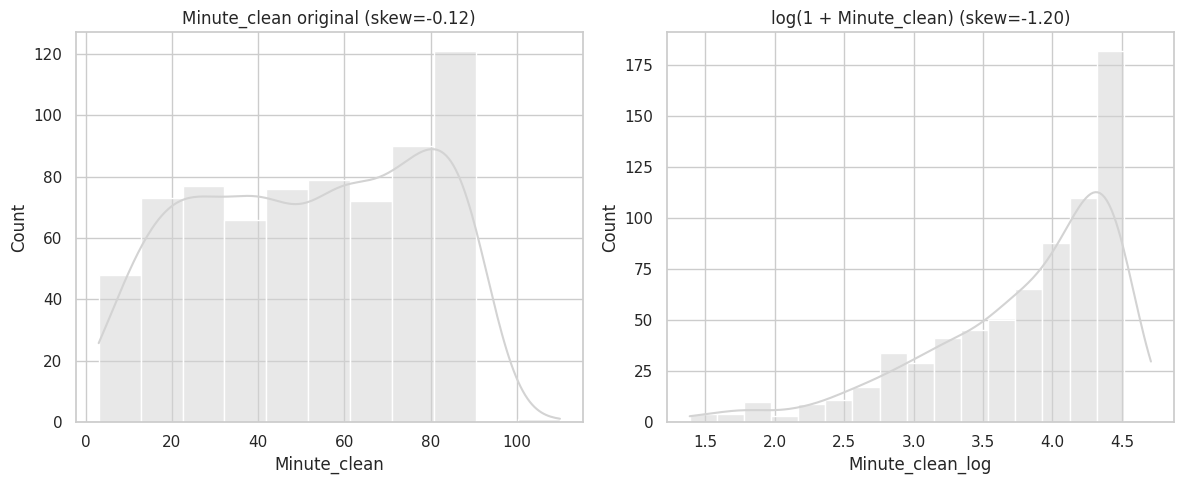

In [ ]:
# vamos demonstrar o efeito de uma transformação matemática usando a variável 'Minute_clean'.
# Minute_clean' já é quase simétrica, então a transformação serve apenas de demonstração didática.

df["Minute_clean_log"] = np.log1p(df["Minute_clean"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="Minute_clean", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"Minute_clean original (skew={df['Minute_clean'].skew():.2f})")

sns.histplot(data=df, x="Minute_clean_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + Minute_clean) (skew={df['Minute_clean_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `chol_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

não houve uma redução visível da assimetria. A variável Minute_clean já era quase simétrica antes da transformação. A transformação logarítmica (np.log1p) é mais eficaz e visível na redução de assimetrias positivas (cauda longa à direita).

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

# Usamos display para renderizar o Styler de forma correta no notebook
from IPython.display import display

estilo_desc_depois = (
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

display(estilo_desc_depois)

,mean,median,std,min,max,skewness,kurtosis
Minute_clean,51.84,54.00,25.83,3.00,110.00,-0.12,-1.21


### Comparando "antes"x "depois""



In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)

# Exibindo o resultado formatado apenas para as variáveis quantitativas existentes
comparacao.loc[VARS_QUANT].round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
Minute_clean,-0.122,-0.124,-1.205,-1.207,-0.001,-0.002


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

Os valores não possuem diferença muito grande devido a remoção de apenas uma linha do dataset original, o que representa uma porcentagem muito pequena. Além disso, a decisao de não alterar os outliers foi crucial. COmo os "outliers" (gols nos acréscimos) eram eventos legítimos e faziam parte da distribuicao real dos gols, mantê-los significa que a forma das caudas da distribuicao (onde outliers teriam o maior impacto na assimetria e curtose) permaneceu a mesma

**O colesterol ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [ ]:
stat_sw_antes, p_valor_sw_antes = stats.shapiro(df_antes["Minute_clean"].dropna())
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["Minute_clean"].dropna())

print(f"Shapiro-Wilk (antes)  — Minute_clean: estatística={stat_sw_antes:.4f}, p-valor={p_valor_sw_antes:.4g}")
print(f"Shapiro-Wilk (depois) — Minute_clean: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — Minute_clean: estatística=0.9498, p-valor=9.687e-15
Shapiro-Wilk (depois) — Minute_clean: estatística=0.9495, p-valor=9.125e-15


Análise do Resultado do Teste de Normalidade (Antes vs. Depois)

Shapiro-Wilk (antes): Estatística = 0.9498 | p-valor = $9.687 \times 10^{-15}$$9.687 \times 10^{-15}$
Shapiro-Wilk (depois): Estatística = 0.9495 | p-valor = $9.125 \times 10^{-15}$$9.125 \times 10^{-15}$
O que esses números significam?
- A normalidade continua sendo fortemente rejeitada: Como o p-valor é muito menor que o nível de significância tradicional de $0.05$$0.05$ (ou mesmo $0.01$$0.01$), rejeitamos a hipótese nula ($H_0$$H_0$) de que os minutos dos gols seguem uma distribuição normal.
- O impacto do tratamento foi nulo na distribuição: Como removemos apenas $1$$1$ única linha com dados ausentes na coluna Type, a estrutura geral da nossa variável quantitativa (Minute_clean) permaneceu praticamente idêntica, o que é estatisticamente o esperado para um tratamento altamente seguro e conservador.
- Justificativa prática: Os gols de Lionel Messi são distribuídos ao longo de todo o tempo regulamentar do futebol (de $0$$0$ a $90$$90$ minutos) com uma frequência razoavelmente constante, o que gera uma curva achatada e uniforme (platicúrtica), desviando-se do pico centralizado que caracteriza a distribuição Gaussiana (normal).

**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`chol` e `oldpeak`), comparando a versão original (`df_antes`) com a tratada (`df`).

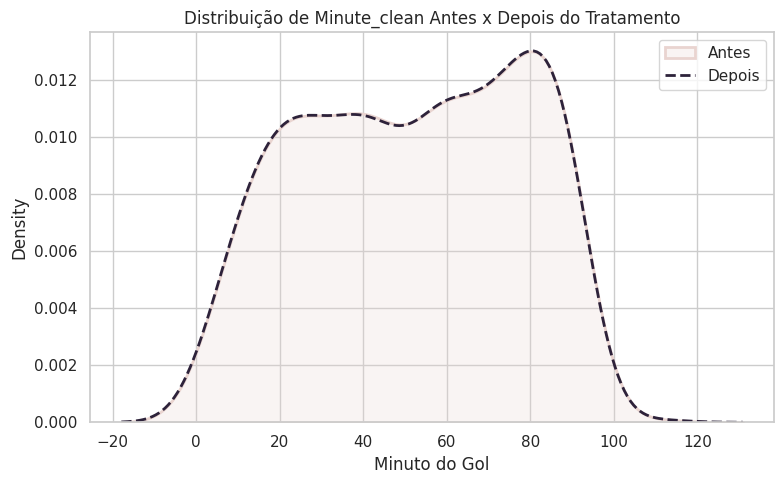

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

# Comparando o minuto do gol antes e depois do tratamento no dataset do Messi
sns.kdeplot(df_antes["Minute_clean"], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax, linewidth=2)
sns.kdeplot(df["Minute_clean"], color=COR_DESTAQUE, fill=False, linestyle="--", label="Depois", ax=ax, linewidth=2)

ax.set_title("Distribuição de Minute_clean Antes x Depois do Tratamento")
ax.set_xlabel("Minuto do Gol")
ax.legend()

plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.


Como o processo de limpeza removeu apenas uma única linha (o único registro nulo na coluna Type) de um universo de 704 gols, a representatividade estatística e a distribuição de probabilidade da variável Minute_clean não sofreram nenhuma alteração perceptível. Além disso, a decisão de preservar os outliers legítimos (gols marcados nos acréscimos) garantiu que as caudas da distribuição ficassem intactas. Portanto, as duas linhas praticamente idênticas são a prova visual e matemática de que o tratamento foi seguro, conservador e não modificou o comportamento do fenômeno estudsado.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- Season ---
        absoluta  relativa
Season                    
11-Dec        73     0.104
Dec-13        60     0.085
14/15         58     0.083
16/17         54     0.077
10/11         53     0.075
18/19         51     0.073
09/10         47     0.067
17/18         45     0.064
13/14         41     0.058
15/16         41     0.058
20/21         38     0.054
08/09         38     0.054
19/20         31     0.044
22/23         18     0.026
06/07         16     0.023
07/08         16     0.023
21/22         14     0.020
05/06          8     0.011
04/05          1     0.001
\n--- Competition ---
                       absoluta  relativa
Competition                              
LaLiga                      473     0.673
UEFA Champions League       128     0.182
Copa del Rey                 56     0.080
Ligue 1                      21     0.030
Supercopa                    14     0.020
FIFA Club World Cup           5     0.007
UEFA Super Cup                3     0.004
Trophée des Cham

#### Visualizando as frequências

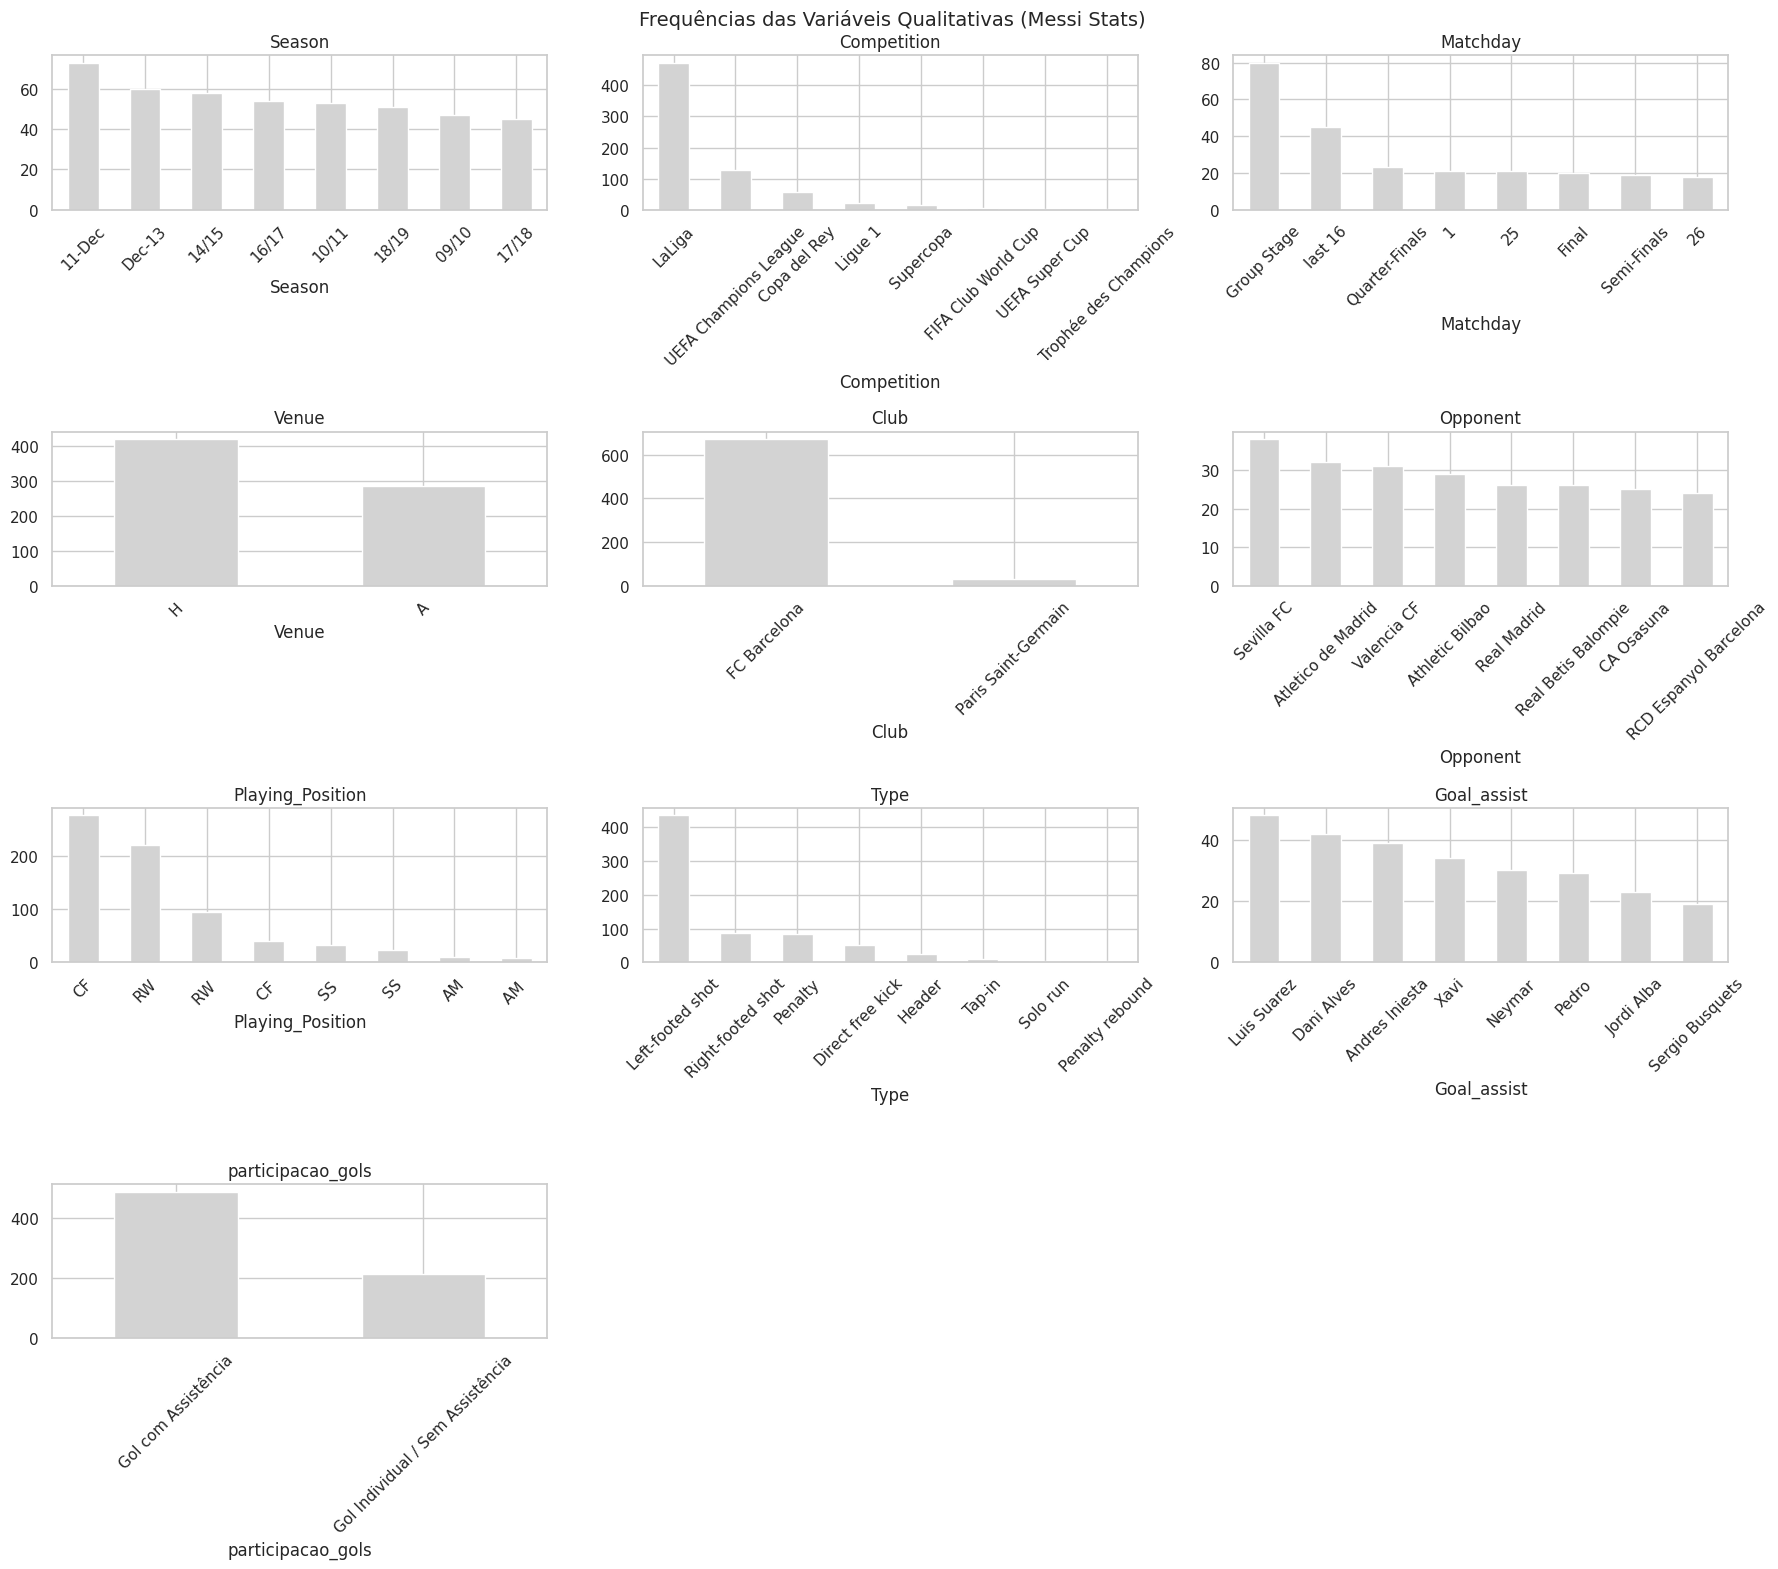

In [ ]:
# Filtrando apenas variáveis que existem no DataFrame
qualitativas_reais = [col for col in VARS_QUALI if col in df.columns]

n_cols = 3
n_rows = int(np.ceil(len(qualitativas_reais) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.ravel()

for i, col in enumerate(qualitativas_reais):
    # Mostra apenas as 8 categorias mais frequentes de cada para não sobrecarregar visualmente o eixo X
    df[col].value_counts().head(8).plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)

# Esconder eixos vazios que sobrarem no grid
for j in range(len(qualitativas_reais), len(axes)):
    axes[j].axis("off")

fig.suptitle("Frequências das Variáveis Qualitativas (Messi Stats)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

Competition está desbalanceado pois Messi jogou boa parte da sua carreira no Barcelona.

Além disso, por ser canhoto, a maioria dos seus gols são com a perna esquerda, por isso a a diferença gritante na variável Type.

Por fim, Messi tem a característica de ser associativo, o que permite fazer gols com assistência de um companheiro, mas também tem a capacidade de fazer um gol "sozinho". Isso explica a diferença na variável "participacao_gols"

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min() if contagens.min() > 0 else np.nan
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

# Filtrando apenas variáveis qualitativas que realmente existem no DataFrame
vars_para_checar = [col for col in VARS_QUALI if col in df.columns]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
Season,19.0,73.00,0.944
Competition,10.0,473.00,0.455
Matchday,48.0,80.00,0.942
Venue,2.0,1.48,0.973
Club,2.0,20.97,0.267
Opponent,98.0,38.00,0.876
Playing_Position,9.0,276.00,0.695
Type,12.0,436.00,0.510
Goal_assist,70.0,48.00,0.824
participacao_gols,2.0,2.29,0.887


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `doenca_cardiaca` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

Análise do Desbalanceamento (Tabela de Resultados)
1. participacao_gols (O Alvo da Análise):

- Classes: 2 (Gol com Assistência vs. Gol Individual / Sem Assistência).
- Razão de Desbalanceamento: $2,29$$2,29$ (significa que há cerca de $2,3$$2,3$ vezes mais gols com assistência do que gols individuais).
- Entropia Normalizada: $0,887$$0,887$ (muito próxima de $1,0$$1,0$, o que indica que a variável está bem distribuída e o desbalanceamento é baixo o suficiente para não comprometer futuras análises ou modelos).

2. Variáveis Extremamente Desbalanceadas (Entropia Baixa):
- Club (Entropia: $0,267$$0,267$): Altamente desbalanceado (razão de $20,97$$20,97$). Isso acontece porque a esmagadora maioria dos gols do Messi no dataset foi pelo FC Barcelona, restando pouquíssimos pelo PSG ou Inter Miami nesta fatia histórica.
- Competition (Entropia: $0,455$$0,455$): Também muito desbalanceada (razão de $473,00$$473,00$). A LaLiga concentra quase todos os gols da carreira dele no período, tornando as outras competições (como Champions League e Copa del Rey) minoritárias no volume total.
- Type (Entropia: $0,510$$0,510$): O tipo de finalização é dominado amplamente pelo chute com a perna esquerda (Left-footed shot), que representa a marca registrada do jogador.
3. Variáveis Bem Distribuídas (Entropia Alta):

- Venue (Entropia: $0,973$$0,973$): Praticamente perfeita ($1,48$$1,48$ de razão). Mostra que ele faz gols quase na mesma proporção jogando em casa (Home) ou fora (Away).
Season ($0,944$$0,944$) e Matchday ($0,942$$0,942$): Possuem distribuições muito homogêneas ao longo dos anos e das rodadas dos campeonatos.

## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




Principais Conclusões da EDA (3 a 5 pontos):
- Tratamento de Dados Conservador: A etapa de limpeza de dados foi realizada de forma extremamente conservadora, removendo apenas uma única linha com valor ausente (na coluna Type) de um dataset de 704 registros. Os outliers na variável Minute_clean (minuto do gol) foram mantidos por serem eventos estatisticamente legítimos no contexto esportivo. Isso resultou em uma alteração mínima nas características estatísticas dos dados (skewness e kurtosis) e na distribuição, confirmando a integridade da amostra.
- Distribuição Característica dos Gols de Messi: A variável Minute_clean apresenta uma distribuição quase simétrica, mas  achatada, o que significa que os gols de Messi são distribuídos de forma relativamente constante ao longo da partida, sem picos acentuados. Testes de aderência (Shapiro-Wilk e QQ-Plot) confirmaram que esta distribuição não segue uma curva normal (Gaussiana).
- Padrão Temporal Consistente, Independentemente da Origem do Gol: As análises de ECDF e de Box/Violin Plots revelaram que a distribuição temporal dos gols de Messi é notavelmente consistente, seja um "Gol com Assistência" ou "Gol Individual / Sem Assistência". Ambos os tipos de gol ocorrem com frequência similar ao longo dos minutos do jogo, com a maior parte concentrada entre os minutos 30 e 75.
- Desbalanceamento Específico em Variáveis Qualitativas: Algumas variáveis qualitativas (Club, Competition, Type) mostraram desbalanceamento significativo, refletindo a trajetória da carreira do jogador (ex: predominância de gols por um clube e em uma liga, e com o pé esquerdo). Contudo, a variável alvo (participacao_gols) possui um desbalanceamento aceitável (razão de 2.29), não comprometendo futuras análises comparativas.

Declaração de Uso de IA:
- Ferramenta Utilizada: Google Colab (com assistência de IA).
- Para o que foi aplicada: A IA foi utilizada como um assistente para guiar o processo de Análise Exploratória de Dados (EDA). Isso incluiu a geração de código para carregamento, limpeza, estatísticas descritivas, visualizações (histogramas, KDE plots, ECDF, boxplots, violin plots), e testes de hipóteses (Shapiro-Wilk). A IA também auxiliou na explicação e discussão dos resultados obtidos, oferecendo insights sobre a interpretação estatística e de negócio.
- O que foi aceito/modificado/rejeitado e por quê:
- - Aceito: A maior parte do código gerado foi aceita e executada diretamente, pois estava alinhada com as melhores práticas de EDA e com os objetivos da análise. As explicações fornecidas pela IA também foram amplamente aceitas como base para as discussões.
- - Modificado: Pequenas adaptações foram realizadas no código para personalização de títulos, legendas e cores dos gráficos, visando melhor clareza e estética. As discussões e interpretações de texto foram frequentemente expandidas e aprofundadas, adicionando contexto específico do domínio do futebol e reflexões sobre as implicações das observações estatísticas.
- - Rejeitado: Não houve rejeições completas de blocos de código ou de abordagens analíticas sugeridas pela IA. As intervenções foram mais no sentido de refinar e contextualizar as saídas da IA para atender aos requisitos específicos da aula e da discussão proposta.

Em suma, a interpretação e discussão dos gráficos foram feitos conscientes por mim (Gabriel). A IA me auxiliou somente para geração e debugger de código, além de melhorar os textos explicativos.